# Total Variation and Image Processing

**Seong Cho** · ACME Volume 4, Lab 20

**Lab objective:** minimizing an energy functional is equivalent to solving the resulting Euler-Lagrange equations; introduce the method of steepest descent to solve these equations, and apply it to a denoising problem in image processing.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## The gradient descent method

Consider an energy functional $J[u] = \int_\Omega L(x, u, \nabla u)\,dx$ over admissible functions $u : \Omega \subset \mathbb{R}^n \to \mathbb{R}$. A minimizer $u^*$ satisfies the Euler-Lagrange equation

$$L_u - \sum_{i=1}^n \frac{\partial L_{u_{x_i}}}{\partial x_i} = L_u - \nabla\cdot L_{\nabla u} = L_u - \operatorname{div}(L_{\nabla u}) = 0, \qquad \textbf{(20.1)}$$

where $L_{\nabla u} = [L_{x_1}, \dots, L_{x_n}]^\intercal$. This is typically an elliptic PDE. Instead of solving it directly, it is often easier to evolve an initial guess by the related parabolic PDE

$$u_t = -(L_y - \operatorname{div} L_{\nabla u}), \quad t > 0, \qquad u(x, 0) = u_0(x), \qquad \textbf{(20.2)}$$

and stop once its steady state, which solves (20.1), is well approximated. For example, $J[u] = \int_\Omega \|\nabla u\|^2\,dx$ has Euler-Lagrange equation $-\Delta u = 0$ and gradient descent flow $u_t = \Delta u$, the heat equation. (Writing the Euler-Lagrange equation as $\Delta u = 0$ would give the backward heat equation $u_t = -\Delta u$, which is ill-posed.)

The flow (20.2) is steepest descent: the first variation is $\delta J(u; h) = \langle L_y(u) - \operatorname{div} L_{\nabla u}(u), h\rangle_{L^2(\Omega)}$, so by Cauchy-Schwarz $h = L_y(u) - \operatorname{div} L_{\nabla u}(u)$ is the direction of steepest ascent and its negative the direction of steepest descent.

## Minimizing the area of a surface of revolution

Revolving a curve $y(x)$ about the $x$-axis gives a surface of area $A[y] = \int_a^b 2\pi y\sqrt{1 + (y')^2}\,dx$. Over smooth curves with fixed end points $y(a) = y_a$, $y(b) = y_b$, the Euler-Lagrange equation is

$$0 = 1 - \frac{yy''}{1 + (y')^2}, \quad\text{i.e.}\quad 0 = 1 + (y')^2 - yy'', \qquad \textbf{(20.3)}$$

with gradient descent flow

$$u_t = -1 - (y')^2 + yy'', \quad t > 0, \ x \in (a,b), \qquad u(x,0) = g(x), \qquad u(a,t) = y_a, \quad u(b,t) = y_b. \qquad \textbf{(20.4)}$$

The spec discretizes (20.4) with second-order centered differences in space and a forward Euler step in time, starting from the straight line between the end points and stepping until successive iterations are close. The minimizing curve is shown in Figure 20.1.

## Problem 1: A minimal surface of revolution

> **Problem 1.** Construct a numerical solution of (20.4) using the conditions $y(-1) = 1$, $y(1) = 7$. Use 20 $x$ steps, 250 time steps, and a final time of .2.
>
> Most numerical schemes have a stability condition that must be satisfied. Our discretization requires that $\frac{\Delta t}{(\Delta x)^2} \leq \frac{1}{2}$. Check that this condition is satisfied.
>
> Let the straight line connecting the endpoints serve as an initial guess, $u$. Iterate through the time steps, updating $u$ according to `u+=dt*u_t` until the norm of the difference between successive iterations is less than $10^{-5}$. Keep in mind the endpoints should not update. Plot the solution that minimizes (20.4). It should match figure 20.1.

In [2]:
x, dx = np.linspace(-1, 1, 21, retstep=True)
t, dt = np.linspace(0, 0.2, 251, retstep=True)
dt / dx**2

np.float64(0.07999999999999999)

In [3]:
g = lambda x: 3*x + 4
u = g(x)
for _ in range(len(t)):
    Du = (u[2:] - u[:-2]) / (2*dx)
    D2u = (u[2:] - 2*u[1:-1] + u[:-2]) / (dx**2)
    u_t = -1 - Du**2 + u[1:-1]*D2u
    u_t = np.hstack([0, u_t, 0])
    u1 = u + dt*u_t
    if np.linalg.norm(u1 - u) < 1e-5:
        break
    u = u1

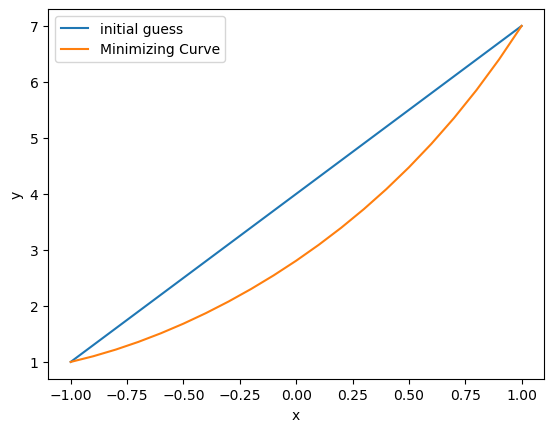

In [4]:
plt.plot(x, g(x), label="initial guess")
plt.plot(x, u, label="Minimizing Curve")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [5]:
Du = (u[2:] - u[:-2]) / (2*dx)
D2u = (u[2:] - 2*u[1:-1] + u[:-2]) / (dx**2)
print("time steps taken:", _ + 1, "  norm of the next update:", np.linalg.norm(dt*(-1 - Du**2 + u[1:-1]*D2u)))

time steps taken: 251   norm of the next update: 0.006772219537733241


## Image processing: denoising

A greyscale image is a function $u : \Omega \to \mathbb{R}$, $\Omega \subset \mathbb{R}^2$ (a color image is three such functions). The spec's code reads an image as floats in $[0, 1]$ and replaces 40000 random pixels with noise.

A first attempt at denoising a noisy image $f$ minimizes

$$J[u] = \int_\Omega L(x, u, \nabla u)\,dx, \qquad L(x,u,\nabla u) = \frac12(u - f)^2 + \frac\lambda2|\nabla u|^2, \qquad \textbf{(20.5)}$$

which penalizes images that are too different from the noisy image and images with large derivatives. The regularization parameter $\lambda$ is our best guess at how much noise was added; some information is irretrievably lost, so denoising is a difficult inverse problem. The Euler-Lagrange equation is $(u - f) - \lambda\Delta u = 0$, with gradient descent flow

$$u_t = -(u - f - \lambda\Delta u), \qquad u(x, 0) = f(x). \qquad \textbf{(20.6)}$$

Discretize $u_t$ with a forward Euler difference and $u_{xx}$, $u_{yy}$ with centered differences, e.g. $u_{xx} \approx (u^n_{i+1,j} - 2u^n_{ij} + u^n_{i-1,j})/\Delta x^2$.

## Problem 2: Diffusion-based denoising

> **Problem 2.** Let u be the grayscale image `balloons_bw.jpg`; remember to scale it when importing.
>
> Using $\Delta t = 10^{-3}$, $\lambda = 40$, $\Delta x = 1$, and $\Delta y = 1$, implement the numerical scheme mentioned above to obtain a denoised solution $u$. (So $\Omega = [0, n_x] \times [0, n_y]$, where $n_x$ and $n_y$ represent the number of pixels in the x and y dimensions, respectively.) Take 250 steps in time. Compare your results with Figure 20.3.
>
> Hint: Use the function `np.roll` to compute the spatial derivatives. For example, the second derivative can be approximated at interior grid points using:
>
> `u_xx = np.roll(u,-1,axis=1) - 2*u + np.roll(u,1,axis=1)`

In [6]:
from imageio.v2 import imread    # [compat]: the top-level imageio.imread is deprecated

imagename = 'balloons_resized_bw.jpg'
changed_pixels=40000
# Read the image file imagename into an array of numbers, IM
# Multiply by 1. / 255 to change the values so that they are floating point
# numbers ranging from 0 to 1.
IM = imread(imagename, mode='F') * (1. / 255)    # [compat]: as_gray=True is no longer supported; mode='F' gives the same grayscale floats
IM_x, IM_y = IM.shape

np.random.seed(0)    # Changed: seed the noise so reruns are reproducible
for lost in range(changed_pixels):
    x_,y_ = np.random.randint(1,IM_x-1), np.random.randint(1,IM_y-1)
    val = .1*np.random.randn() + .5
    IM[x_,y_] = max( min(val,1.), 0.)

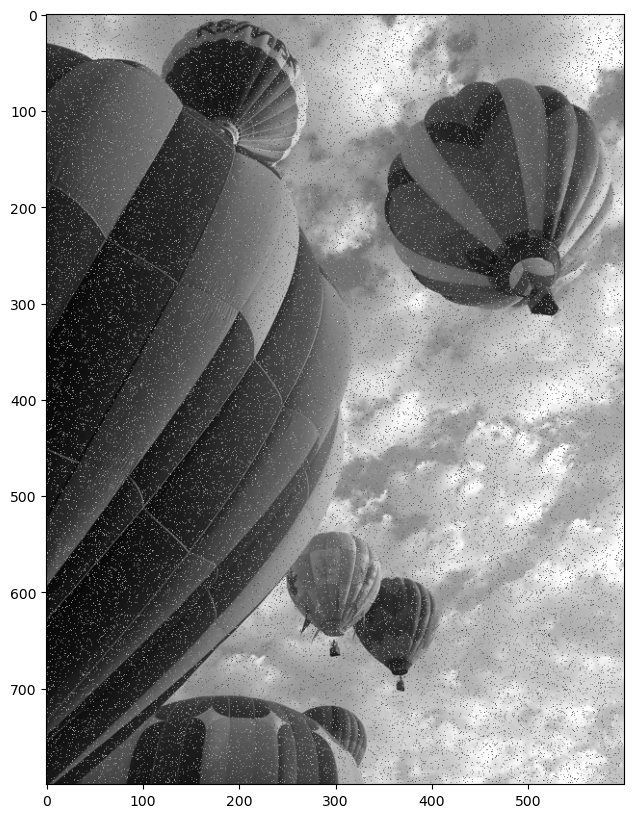

In [7]:
plt.figure(figsize=(10,10))
plt.imshow(IM, cmap="gray")
plt.show()

In [8]:
f = np.array(IM)
u = f.copy()    # Changed: was u = f, so u += ... also changed f and the u - f term was always 0
dt = 1e-3
_lambda = 40
dx = 1
dy = 1
for _ in range(250):
    u_xx = np.roll(u,-1,axis=1) - 2*u + np.roll(u,1,axis=1)
    u_yy = np.roll(u,-1,axis=0) - 2*u + np.roll(u,1,axis=0)
    u_t = -(u - f - _lambda*(u_xx + u_yy))
    u+=dt*u_t

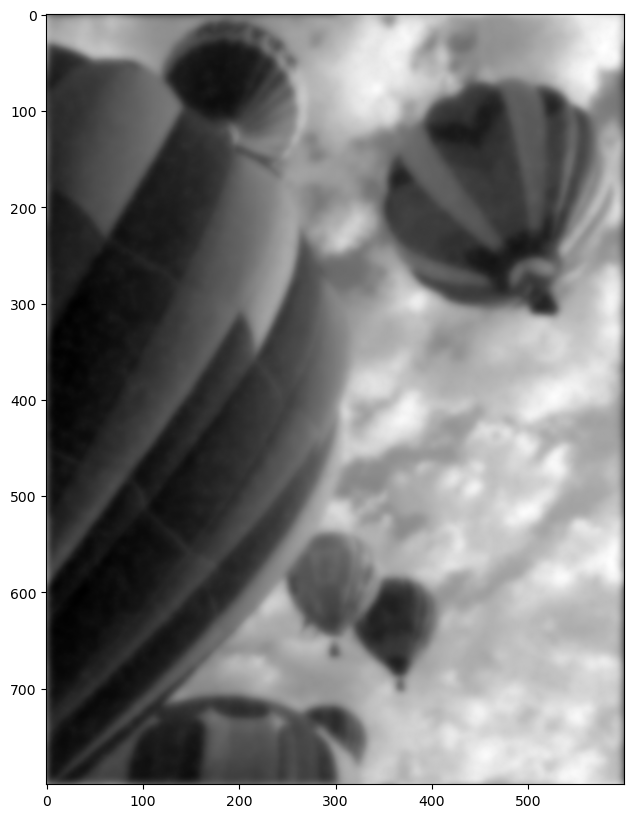

In [9]:
plt.figure(figsize=(10,10))
plt.imshow(u, cmap="gray")
plt.show()

## Image processing: the total variation method

A $C^1$ function $u : \Omega \to \mathbb{R}$ has bounded total variation, $u \in BV(\Omega)$, if $\int_\Omega |\nabla u| < \infty$, and its total variation is $\int_\Omega |\nabla u|$; adding noise increases it. Rudin, Osher and Fatemi (1992) find a denoised image $u$ minimizing

$$\int_\Omega |\nabla u(x)|\,dx \qquad \textbf{(20.7)}$$

subject to

$$\int_\Omega u(x)\,dx = \int_\Omega f(x)\,dx, \qquad \textbf{(20.8)}$$
$$\int_\Omega |u(x) - f(x)|^2\,dx = \sigma|\Omega|. \qquad \textbf{(20.9)}$$

(20.8) says the noise has zero mean, and (20.9), with $\sigma$ chosen a priori as the standard deviation of the noise, keeps $u$ from collapsing to the constant mean of $f$. Chambolle and Lions proved that this is equivalent to

$$F[u] = \min_{u \in BV(\Omega)} \int_\Omega |\nabla u| + \frac\lambda2(u - f)^2\,dx \qquad \textbf{(20.10)}$$

for a fixed regularization parameter $\lambda > 0$. Using $\int|\nabla u|$ instead of $\int|\nabla u|^2$ makes a huge difference: it tends to preserve edges and boundaries of objects in the image. The gradient descent flow is

$$u_t = -\lambda(u - f) + \frac{u_{xx}u_y^2 + u_{yy}u_x^2 - 2u_xu_yu_{xy}}{(u_x^2 + u_y^2)^{3/2}}, \qquad u(x, 0) = f(x). \qquad \textbf{(20.11)}$$

To remove the singularity where $|\nabla u| = 0$, replace $|\nabla u|^3$ in the denominator with $(\varepsilon + |\nabla u|^2)^{3/2}$.

## Problem 3: Total variation denoising

> **Problem 3.** Using $\Delta t = 10^{-3}$, $\lambda = 1$, $\Delta x = 1$, and $\Delta y = 1$, implement the numerical scheme mentioned above to obtain a solution $u$. Take 200 steps in time. Compare your results with Figure 20.3. How small should $\epsilon$ be?
>
> Hint: To compute the spatial derivatives, consider the following:
>
> `u_x = (np.roll(u,-1,axis=1) - np.roll(u,1,axis=1))/2`
>
> `u_xx = np.roll(u,-1,axis=1) - 2*u + np.roll(u,1,axis=1)`
>
> `u_xy = (np.roll(u_x,-1,axis=0) - np.roll(u_x,1,axis=0))/2.`

In [10]:
dt = 1e-3
_lambda = 1
eps = 1e-5
f = np.array(IM)
u = f.copy()    # Changed: was u = f, so u += ... also changed f and the u - f term was always 0
for _ in range(200):
    u_x = (np.roll(u,-1,axis=1) - np.roll(u,1,axis=1))/2
    u_y = (np.roll(u,-1,axis=0) - np.roll(u,1,axis=0))/2
    u_xx = np.roll(u,-1,axis=1) - 2*u + np.roll(u,1,axis=1)
    u_xy = (np.roll(u_x,-1,axis=0) - np.roll(u_x,1,axis=0))/2
    u_yy = np.roll(u,-1,axis=0) - 2*u + np.roll(u,1,axis=0)
    denom = (eps + u_x**2 + u_y**2)**(3/2)
    u_t = -_lambda*(u - f) + \
          (u_xx*u_y**2 + u_yy*u_x**2 - 2*u_x*u_y*u_xy) / denom
    u+=dt*u_t

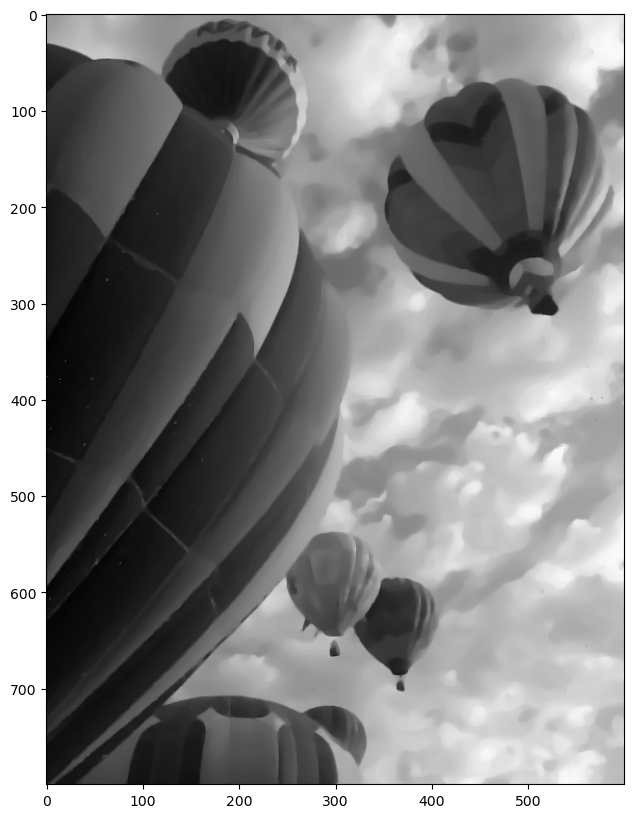

In [11]:
plt.figure(figsize=(10,10))
plt.imshow(u, cmap="gray")
plt.show()

In [12]:
tv = lambda v: np.sum(np.hypot(np.diff(v, axis=0)[:, :-1], np.diff(v, axis=1)[:-1]))
print("total variation of the noisy image:   ", tv(f))
print("total variation of the denoised image:", tv(u))

total variation of the noisy image:    38710.8
total variation of the denoised image: 4554.955
